# Connect G-Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ROOT_DIR = "/content/drive/MyDrive/Colab Notebooks/doraemon yolo11"

Mounted at /content/drive


## Setup Dependency

In [ ]:
!pip install roboflow ultralytics pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 23.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


# Merge Dataset

In [ ]:
import os
import shutil
from roboflow import Roboflow

# --- CONFIGURATION ---
ROBOFLOW_API_KEY = ""
WORKSPACE_NAME="dethzworkspace"
PROJECT_NAME = "fujiko-pni1u"
VERSIONS_TO_MERGE = [1, 2]  # Add all version numbers you want to combine
# ---------------------

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

# Create a master dataset directory structure
master_dir = ROOT_DIR + "/main_dataset"
for split in ['train', 'valid', 'test']:
    os.makedirs(f"{master_dir}/{split}/images", exist_ok=True)
    os.makedirs(f"{master_dir}/{split}/labels", exist_ok=True)

# Download and merge each version
for version in VERSIONS_TO_MERGE:
    print(f"--- Downloading version {version} ---")
    dataset = project.version(version).download("yolov11")
    downloaded_path = dataset.location

    # Copy files into the master dataset directory
    for split in ['train', 'valid', 'test']:
        img_src = f"{downloaded_path}/{split}/images"
        lbl_src = f"{downloaded_path}/{split}/labels"

        if os.path.exists(img_src):
            for img in os.listdir(img_src):
                # Prefixed name prevents overwriting if filenames are identical across versions
                new_name = f"v{version}_{img}"
                shutil.copy(f"{img_src}/{img}", f"{master_dir}/{split}/images/{new_name}")

                # Check for corresponding label file
                lbl_name = img.rsplit('.', 1)[0] + '.txt'
                if os.path.exists(f"{lbl_src}/{lbl_name}"):
                    shutil.copy(f"{lbl_src}/{lbl_name}", f"{master_dir}/{split}/labels/v{version}_{lbl_name}")

    # Copy the data.yaml from the first version to serve as our base config
    if version == VERSIONS_TO_MERGE[0]:
        shutil.copy(f"{downloaded_path}/data.yaml", f"{master_dir}/data.yaml")

print("Successfully merged all versions into " + master_dir + "!")


loading Roboflow workspace...
loading Roboflow project...
--- Downloading version 1 ---
/content/Fujiko-1
--- Downloading version 2 ---
Successfully merged all versions into /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/main_dataset!


# Training

In [ ]:
from ultralytics import YOLO

# Load a model
model = YOLO("yolo11n.pt")

# Train the model
model.train(
    data=master_dir+ "/data.yaml",  # path to dataset YAML
    epochs=20,  # number of training epochs
    imgsz=640,  # image size for training
    batch=16,  # batch size
    lr0=0.001,  # initial learning rate
    device="0"  # device to train on 0 (GPU) หรือ cpu
)


# ประเมินโมเดล (Evaluate model performance on the validation set)
metrics = model.val()


# บันทึกโมเดลที่ฝึกเสร็จแล้ว
model.save(ROOT_DIR + '/best.pt')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/doraemon yolo11/main_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.

# Export Model to ONNX

In [ ]:
# โหลดโมเดลที่ดีที่สุดจาก training
best_model = YOLO(ROOT_DIR + '/best.pt')

# Export เป็น ONNX
onnx_model = best_model.export(
    format="onnx",
    imgsz=640,
    opset=12,
    simplify=True
)

print("ONNX model saved:", onnx_model)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Colab Notebooks/doraemon yolo11/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 265ms
Prepared 4 packages in 522ms
Installed 4 packages in 34ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12..

# Test model

=== Starting Model Inference and Exporting Report ===
Testing: sample_02.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_02.jpg: 384x640 1 doraemon, 1 jaian, 1 nobita, 1 shizuka, 1 suneo, 9.2ms
Speed: 2.2ms preprocess, 9.2ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


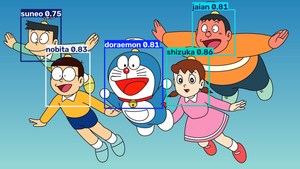

Testing: sample_04.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_04.jpg: 640x480 1 doraemon, 1 jaian, 2 nobitas, 1 shizuka, 1 suneo, 50.9ms
Speed: 2.0ms preprocess, 50.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


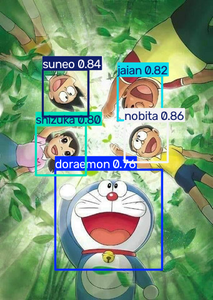

Testing: sample_01.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_01.jpg: 384x640 1 doraemon, 1 jaian, 1 nobita, 1 shizuka, 1 suneo, 12.5ms
Speed: 2.0ms preprocess, 12.5ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


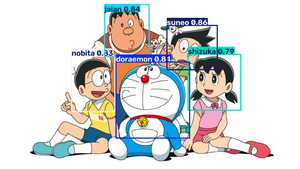

Testing: sample_05.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_05.jpg: 384x640 1 doraemon, 1 jaian, 2 nobitas, 1 shizuka, 1 suneo, 9.6ms
Speed: 2.1ms preprocess, 9.6ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


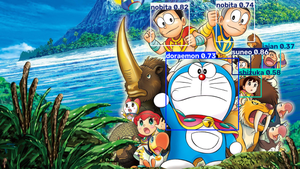

Testing: sample_07.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_07.jpg: 384x640 1 doraemon, 1 shizuka, 9.1ms
Speed: 1.8ms preprocess, 9.1ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


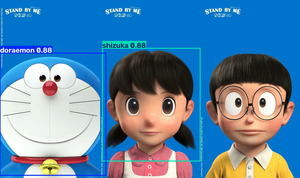

Testing: sample_09.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_09.jpg: 384x640 1 doraemon, 14.3ms
Speed: 2.7ms preprocess, 14.3ms inference, 2.5ms postprocess per image at shape (1, 3, 384, 640)


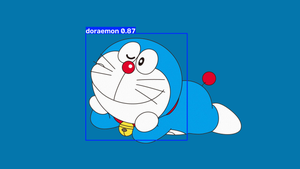

Testing: sample_03.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_03.jpg: 480x640 1 jaian, 1 nobita, 2 shizukas, 1 suneo, 49.6ms
Speed: 2.1ms preprocess, 49.6ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


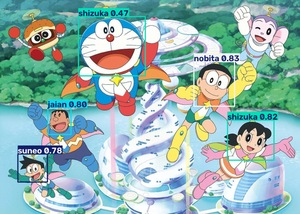

Testing: sample_06.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_06.jpg: 512x640 1 doraemon, 1 jaian, 1 nobita, 1 shizuka, 1 suneo, 49.3ms
Speed: 1.8ms preprocess, 49.3ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 640)


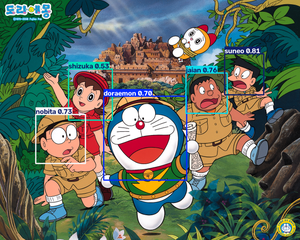

Testing: sample_08.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_08.jpg: 640x320 1 doraemon, 49.7ms
Speed: 1.7ms preprocess, 49.7ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 320)


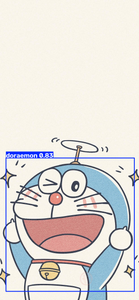

Testing: sample_10.jpg

image 1/1 /content/drive/MyDrive/Colab Notebooks/doraemon yolo11/test/sample_10.jpg: 544x640 1 doraemon, 191.8ms
Speed: 15.6ms preprocess, 191.8ms inference, 6.0ms postprocess per image at shape (1, 3, 544, 640)


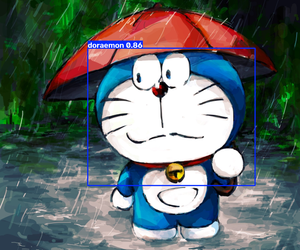

In [ ]:
from ultralytics import YOLO
import os
import sys
from PIL import Image

# โหลดโมเดล
model = YOLO(ROOT_DIR + '/best.pt')

sample_path = ROOT_DIR + '/test'
log_file_path = os.path.join(ROOT_DIR, 'test_log.txt')
pdf_output_path = os.path.join(ROOT_DIR, 'test_results.pdf')

# นามสกุลไฟล์รูปภาพที่รองรับ
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# ติดตั้ง ReportLab สำหรับการสร้าง PDF หากยังไม่มี
try:
    from reportlab.lib.pagesizes import letter
    from reportlab.platypus import SimpleDocTemplate, Image as RLImage, Paragraph, Spacer
    from reportlab.lib.styles import getSampleStyleSheet
except ImportError:
    !pip install reportlab
    from reportlab.lib.pagesizes import letter
    from reportlab.platypus import SimpleDocTemplate, Image as RLImage, Paragraph, Spacer
    from reportlab.lib.styles import getSampleStyleSheet

# ตัวช่วยบันทึก Log ลงทั้งหน้าจอและไฟล์
class Logger(object):
    def __init__(self, filename):
        self.terminal = sys.stdout
        self.log = open(filename, "w", encoding="utf-8")

    def write(self, message):
        self.terminal.write(message)
        self.log.write(message)

    def flush(self):
        self.terminal.flush()
        self.log.flush()

# เริ่มบันทึก Log
sys.stdout = Logger(log_file_path)

print("=== Starting Model Inference and Exporting Report ===")

pdf_elements = []
styles = getSampleStyleSheet()
pdf_elements.append(Paragraph("YOLO11 Model Test Report", styles['Title']))
pdf_elements.append(Spacer(1, 20))

temp_images = []

if os.path.exists(sample_path):
    image_files = [f for f in os.listdir(sample_path) if f.lower().endswith(valid_extensions)]

    if len(image_files) == 0:
        print(f"No images found in {sample_path}")
        pdf_elements.append(Paragraph(f"No images found in sample path.", styles['Normal']))
    else:
        for img_name in image_files:
            img_path = os.path.join(sample_path, img_name)
            print(f"Testing: {img_name}")
            pdf_elements.append(Paragraph(f"File Name: {img_name}", styles['Heading3']))

            # ทำนายผลลัพธ์
            results = model(img_path)

            for i, r in enumerate(results):
                im_array = r.plot()  # plot BGR numpy array
                im = Image.fromarray(im_array[..., ::-1])  # RGB PIL image

                # ปรับขนาดภาพให้ด้านยาวที่สุดมีขนาด 300px โดยรักษาสัดส่วนภาพ (Aspect Ratio)
                max_size = 300
                im.thumbnail((max_size, max_size), Image.Resampling.LANCZOS)

                # บันทึกภาพชั่วคราวเพื่อใส่ใน PDF
                temp_img_path = f"temp_result_{img_name}_{i}.png"
                im.save(temp_img_path)
                temp_images.append(temp_img_path)

                # เพิ่มข้อมูลและรูปภาพลง PDF
                pdf_elements.append(RLImage(temp_img_path))
                pdf_elements.append(Spacer(1, 15))

                # แสดงภาพบน Jupyter Screen ด้วย
                display(im)
else:
    print(f"Directory does not exist: {sample_path}")
    pdf_elements.append(Paragraph(f"Directory does not exist: {sample_path}", styles['Normal']))

# สร้างไฟล์ PDF
doc = SimpleDocTemplate(pdf_output_path, pagesize=letter)
doc.build(pdf_elements)

# ลบรูปภาพชั่วคราวออก
for temp_p in temp_images:
    if os.path.exists(temp_p):
        os.remove(temp_p)

print(f"\n=== Process Finished ===")
print(f"Log saved to: {log_file_path}")
print(f"PDF report saved to: {pdf_output_path}")

# รีเซ็ตระบบ stdout คืนค่าปกติ
sys.stdout = sys.__stdout__